# NYC Taxi Trip Duration - Model Building

Uses the train/test split and the 29 features selected in `feature_engineering.ipynb`
(run that notebook first; it writes `outputs/`). The target is `trip_duration_log = log1p(trip_duration)`,
so the RMSE on the target is the RMSLE used by the Kaggle competition.

Every model is fitted on the training split only and scored once on the held-out 20%.

In [1]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES
# ============================================================

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# ============================================================
# CELL 2 - LOAD FEATURE ENGINEERING OUTPUTS
# ============================================================

possible_dirs = [Path("../outputs"), Path("outputs")]
out_dir = next((p for p in possible_dirs if (p / "X_train_selected.csv").exists()), None)
if out_dir is None:
    raise FileNotFoundError("outputs/ not found - run notebooks/feature_engineering.ipynb first.")

X_train = pd.read_csv(out_dir / "X_train_selected.csv")
X_test = pd.read_csv(out_dir / "X_test_selected.csv")
y_train = pd.read_csv(out_dir / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(out_dir / "y_test.csv").squeeze("columns")

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Target:", y_train.name)
print("Same feature columns in train and test:", list(X_train.columns) == list(X_test.columns))


X_train: (583431, 29)  X_test: (145858, 29)
Target: trip_duration_log
Same feature columns in train and test: True


In [3]:
# ============================================================
# CELL 3 - SANITY CHECKS
# ============================================================

print("Missing values  train:", int(X_train.isna().sum().sum()), " test:", int(X_test.isna().sum().sum()))
print("Infinite values train:", int(np.isinf(X_train.to_numpy()).sum()), " test:", int(np.isinf(X_test.to_numpy()).sum()))

seconds = np.expm1(y_train)
print("\nTraining trip duration (minutes):")
display((seconds / 60).describe(percentiles=[0.01, 0.5, 0.99]).round(2).to_frame("minutes").T)


Missing values  train: 0  test: 0
Infinite values train: 0  test: 0

Training trip duration (minutes):


,count,mean,std,min,1%,50%,99%,max
minutes,583431.0,15.87,66.96,0.02,1.45,11.05,57.17,32328.93


In [4]:
# ============================================================
# CELL 4 - EVALUATION HELPER
# ============================================================

def evaluate(name, model, fit_seconds):
    pred_log = model.predict(X_test)
    pred_s, true_s = np.expm1(pred_log), np.expm1(y_test)
    return {
        "model": name,
        "rmsle": float(np.sqrt(mean_squared_error(y_test, pred_log))),
        "r2_log": float(r2_score(y_test, pred_log)),
        "mae_minutes": float(mean_absolute_error(true_s, pred_s) / 60),
        "median_abs_error_minutes": float(np.median(np.abs(true_s - pred_s)) / 60),
        "fit_seconds": round(fit_seconds, 1),
    }


results, fitted = [], {}


In [5]:
# ============================================================
# CELL 5 - TRAIN AND COMPARE MODELS
# ============================================================

models = {
    "Baseline (training mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (alpha=1.0)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=20, min_samples_leaf=5, max_samples=0.5,
        n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=500, learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=40,
        l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
        random_state=RANDOM_STATE),
}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fitted[name] = model
    results.append(evaluate(name, model, time.perf_counter() - start))
    print(f"{name:<26} RMSLE {results[-1]['rmsle']:.4f}")

comparison = pd.DataFrame(results).sort_values("rmsle").reset_index(drop=True)
display(comparison.round(4))


Baseline (training mean)   RMSLE 0.7912


Linear Regression          RMSLE 0.5279


Ridge (alpha=1.0)          RMSLE 0.5279


Random Forest              RMSLE 0.4021


HistGradientBoosting       RMSLE 0.3900


,model,rmsle,r2_log,mae_minutes,median_abs_error_minutes,fit_seconds
0,HistGradientBoosting,0.3900,0.7570,4.8320,1.8007,14.7
1,Random Forest,0.4021,0.7417,4.9943,1.9136,91.7
2,Ridge (alpha=1.0),0.5279,0.5548,6.4910,2.8354,0.4
3,Linear Regression,0.5279,0.5548,6.4910,2.8354,0.8
4,Baseline (training mean),0.7912,-0.0000,9.3190,5.0699,0.0


In [6]:
# ============================================================
# CELL 6 - SELECT BEST MODEL
# ============================================================

best_name = comparison.loc[0, "model"]
best = fitted[best_name]
baseline = comparison.set_index("model").loc["Baseline (training mean)"]
best_row = comparison.loc[0]

print("Best model:", best_name)
print(f"RMSLE {best_row.rmsle:.4f} vs baseline {baseline.rmsle:.4f} "
      f"({(1 - best_row.rmsle / baseline.rmsle) * 100:.1f}% lower)")
print(f"MAE {best_row.mae_minutes:.2f} min vs baseline {baseline.mae_minutes:.2f} min")
if best_name == "HistGradientBoosting":
    print("Boosting iterations used (early stopping):", best.n_iter_)


Best model: HistGradientBoosting
RMSLE 0.3900 vs baseline 0.7912 (50.7% lower)
MAE 4.83 min vs baseline 9.32 min
Boosting iterations used (early stopping): 429


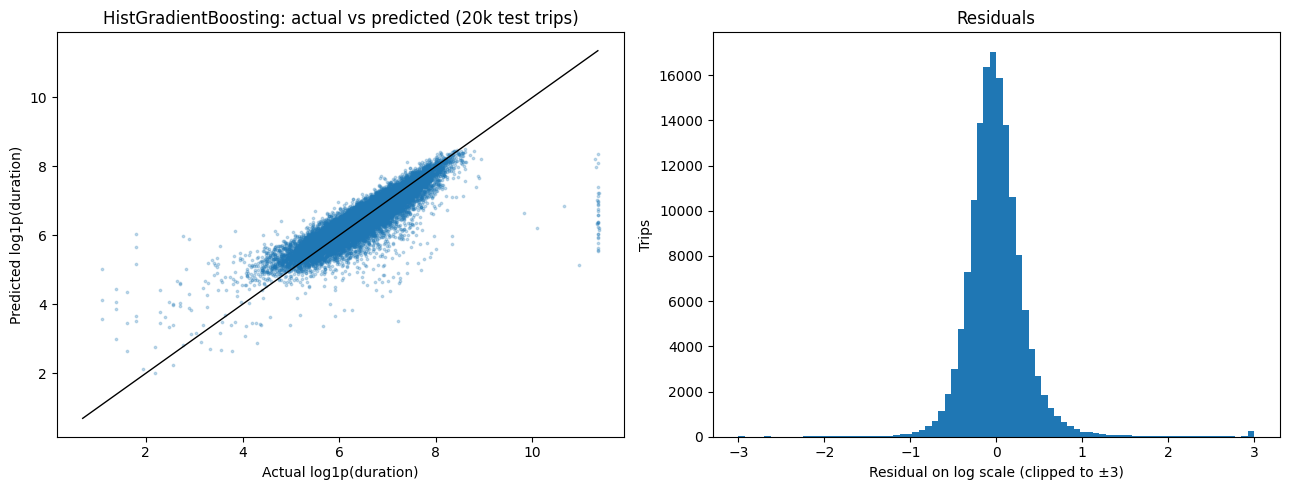

In [7]:
# ============================================================
# CELL 7 - ACTUAL VS PREDICTED
# ============================================================

pred_s = np.expm1(best.predict(X_test))
true_s = np.expm1(y_test)

rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(y_test), size=20000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test.iloc[idx], np.log1p(pred_s[idx]), s=3, alpha=0.25)
lims = [y_test.min(), np.percentile(y_test, 99.9)]
axes[0].plot(lims, lims, color="black", linewidth=1)
axes[0].set(xlabel="Actual log1p(duration)", ylabel="Predicted log1p(duration)",
            title=f"{best_name}: actual vs predicted (20k test trips)")

resid = y_test - np.log1p(pred_s)
axes[1].hist(resid.clip(-3, 3), bins=80)
axes[1].set(xlabel="Residual on log scale (clipped to ±3)", ylabel="Trips", title="Residuals")
plt.tight_layout()
plt.show()


In [8]:
# ============================================================
# CELL 8 - ERROR BY TRIP LENGTH
# ============================================================

bands = pd.cut(true_s / 60, bins=[0, 5, 10, 20, 40, 60, np.inf],
               labels=["<5 min", "5-10", "10-20", "20-40", "40-60", "60+ min"])
by_band = pd.DataFrame({"band": bands, "abs_err_min": np.abs(true_s - pred_s) / 60,
                        "sq_log_err": (y_test - np.log1p(pred_s)) ** 2})
band_table = by_band.groupby("band", observed=True).agg(
    trips=("abs_err_min", "size"),
    mae_minutes=("abs_err_min", "mean"),
    rmsle=("sq_log_err", lambda s: np.sqrt(s.mean())),
).round(3)
display(band_table)


,trips,mae_minutes,rmsle
band,,,
<5 min,22151,1.255,0.498
5-10,43164,1.679,0.284
10-20,51077,2.697,0.293
20-40,24616,5.128,0.347
40-60,3640,10.029,0.436
60+ min,1210,251.253,2.065


,feature,rmsle_increase,std
0,trip_distance_km,0.5507,0.0029
1,direction_angle,0.0763,0.0009
2,pickup_hour,0.0451,0.0011
3,dropoff_latitude,0.0226,0.0006
4,lat_diff,0.0225,0.0007
5,manhattan_distance_km,0.0174,0.0001
6,avg_duration_by_dayofweek,0.0158,0.0002
7,is_office_hour,0.0150,0.0005
8,distance_weekend_interaction,0.0138,0.0006
9,pickup_latitude,0.0125,0.0003


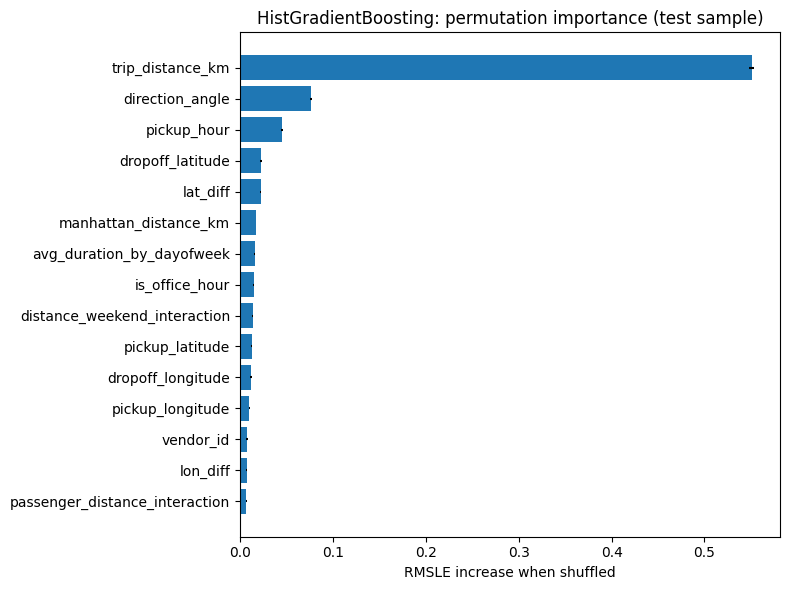

In [9]:
# ============================================================
# CELL 9 - PERMUTATION IMPORTANCE
# ============================================================

# permutation importance on a 20k-row test sample: how much RMSLE worsens when a feature is shuffled
sample = rng.choice(len(X_test), size=20000, replace=False)
perm = permutation_importance(best, X_test.iloc[sample], y_test.iloc[sample],
                              scoring="neg_root_mean_squared_error", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": X_test.columns, "rmsle_increase": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("rmsle_increase", ascending=False).reset_index(drop=True))
display(importance.head(15).round(4))

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["rmsle_increase"], xerr=top["std"])
plt.xlabel("RMSLE increase when shuffled")
plt.title(f"{best_name}: permutation importance (test sample)")
plt.tight_layout()
plt.show()


In [10]:
# ============================================================
# CELL 10 - SAVE METRICS
# ============================================================

reports_dir = out_dir.parent / "reports"
reports_dir.mkdir(exist_ok=True)
metrics = {
    "target": "log1p(trip_duration_seconds)",
    "split": "random 80/20, random_state=42 (from feature_engineering.ipynb)",
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "features": int(X_train.shape[1]),
    "best_model": best_name,
    "models": comparison.round(4).to_dict(orient="records"),
    "best_rmsle_reduction_vs_baseline_pct": round(float((1 - best_row.rmsle / baseline.rmsle) * 100), 1),
    "error_by_trip_length": band_table.reset_index().astype({"band": str}).to_dict(orient="records"),
    "top_features": importance.head(10)[["feature", "rmsle_increase"]].round(4).to_dict(orient="records"),
}
(reports_dir / "model_metrics.json").write_text(json.dumps(metrics, indent=2))
print("Saved:", reports_dir / "model_metrics.json")


Saved: ..\reports\model_metrics.json


In [11]:
# ============================================================
# CELL 11 - CONCLUSION
# ============================================================

print("MODEL BUILDING SUMMARY")
print("=" * 70)
print(f"Best model           : {best_name}")
print(f"Test RMSLE           : {best_row.rmsle:.4f}  (baseline {baseline.rmsle:.4f})")
print(f"Test R² (log scale)  : {best_row.r2_log:.4f}")
print(f"Test MAE             : {best_row.mae_minutes:.2f} minutes")
print(f"Median absolute error: {best_row.median_abs_error_minutes:.2f} minutes")
print(f"Strongest feature    : {importance.loc[0, 'feature']}")
print("\nLimitations: straight-line distances only; no traffic, weather or route data;")
print("a random split (not by time), so the score reflects trips from the same months as training.")


MODEL BUILDING SUMMARY
Best model           : HistGradientBoosting
Test RMSLE           : 0.3900  (baseline 0.7912)
Test R² (log scale)  : 0.7570
Test MAE             : 4.83 minutes
Median absolute error: 1.80 minutes
Strongest feature    : trip_distance_km

Limitations: straight-line distances only; no traffic, weather or route data;
a random split (not by time), so the score reflects trips from the same months as training.
